# Limitation 1 — The finite window

**A window is not an infinite line. Along the scan it has an edge, 18 samples from end to end; across the scan it has a width, and a source outside that width is not in the window at all. The atoms assume a source well inside: the images lay every sample back over the whole sky, and the likelihood puts every source into every window.**

Every limitation notebook has the same four parts. **The premise** states
what the atoms assume and shows the case that breaks it. Then **one section
per atom**, always in the same order, the two images of the windows, the map
of detections, the joint fit, each answering three questions: what does this
atom assume here, what does it return in this case, and does it warn you.
**The summary table** closes with the same columns every time: atom, effect,
alarm, remedy.

The case of this page: two companions, one per case. Case A, positional truncation: a companion at 520 mas, past the last sample center in the scans along the pair axis, where the window records three fifths of its light with the recorded center shifted inward. Case B, flux truncation: a companion of flux 400 at 1120 mas, outside Gaia's across-scan half-width of 1061 mas in the scans near the perpendicular to the pair; in 16 of 80 windows it is on the along-scan grid but not in the window.

| block | task | calls | paper |
|---|---|---|---|
| setup | the toy instrument, the helpers, the two cases | `ins.Instrument.gaussian`, `ins.render_window`, `sim.simulate_window`, `joint.scene_positions_al` | Sect. 2.1, Eqs. 3–4 |
| 1 | the premise: the window's footprint on the sky, case A (the edge), case B (the width) | `ins.project_al`, `inst.design_columns` | Sect. 2.1, Eq. 3; the two cases are not in the paper |
| 2 | the two images | `radon.filtered_backprojection`, `radon.faststack` | App. C.2, Eq. C.3 |
| 3 | the map of detections | `bp.map_peak` | Sect. 3.3, Eq. 13 |
| 4 | the joint fit, and the flux-loss cut | `joint.fit_joint`, `joint.joint_fisher`, `joint.joint_covariance` | Sect. 4.3, Eq. 18 |

Every scanlib call carries the name of its module (`joint.fit_joint`); the first code cell lists the modules.

**The series.** The three images and the fit are in [`../00_three_images_and_fit.ipynb`](../00_three_images_and_fit.ipynb). The limitations: this page, [2 — the scan law](02_scan_law.ipynb), [3 — one line, two lines, three](03_few_lines.ipynb), [4 — a scene that moves](04_motion.ipynb), [5 — the blend](05_blend.ipynb), [6 — errors of the model, and the noise](06_model_errors.ipynb).

**Symbols and units** are defined once for the package and every notebook in [`docs/conventions.md`](../../../docs/conventions.md). This page uses ψ, (Δα\*, Δδ), η, ζ, the grid and the LSF, flux, σ and S/N, ρ and φ, σ_η and the detections, the two images, the map and its width, θ, the Fisher σ and ellipse, the pull, and χ²/dof.

In [1]:
# the imports: numpy, matplotlib, and the scanlib modules; every scanlib call below carries its module's name
import numpy as np
import matplotlib.pyplot as plt

from scanlib import instrument as ins      # the instrument: sampling, LSF, the along-scan projection (Eq. 9)
from scanlib import simulation as sim      # synthetic scenes and their windows
from scanlib import backprojection as bp   # the triangulation map and its peak
from scanlib import radon                  # the inverse Radon transform and faststack
from scanlib import joint                  # the joint fit of all windows, and its helpers

In [2]:
# the paper's figure style: font 10, ticks 9 and inward, thin axes; grays first, one accent
plt.rcParams.update({"font.size": 10.0, "axes.linewidth": 0.5, "xtick.labelsize": 9.0, "ytick.labelsize": 9.0,
                     "xtick.direction": "in", "ytick.direction": "in", "legend.frameon": False, "legend.fontsize": 7.5})
ACCENT = "tomato"                                          # the one accent
# the markers: each name below in capitals with dict(...) is a table of the keywords that ax.scatter takes for
# one kind of point
TRUTH = dict(marker="*", s=150, facecolor="white", edgecolor="k", lw=0.8, zorder=7)   # the truth
FIT = dict(marker="x", s=70, color="k", lw=1.5, zorder=8)                             # a measurement (the joint fit)
PRIMARY = dict(marker="+", s=110, color="k", lw=1.4, zorder=6)                       # the primary
# the labels of the two sky axes
EAST = r"$\Delta\alpha^{*}$  [mas]   (East $\leftarrow$)"
NORTH = r"$\Delta\delta$  [mas]"


def letter(ax, label, text=""):
    """Write a panel's letter, bold, inside the panel's top-left corner, and a few words after it.

    Inputs
        ax      the panel (a matplotlib Axes)
        label   the panel's letter, for example "a"
        text    the words after the letter (default: none)
    Returns nothing: the letter and the words are drawn on ax, on a white box that dims what is under them."""
    white_box = dict(fc="white", ec="none", pad=1.0, alpha=0.8)
    ax.text(0.04, 0.96, rf"$\bf{{({label})}}$ " + text, transform=ax.transAxes, va="top", ha="left", fontsize=9,
            bbox=white_box)

In [3]:
# the toy instrument, the noise, the pair's position angle and fluxes, the two sets of scan directions, and the
# sky grid of every image
FWHM = 100.0                                 # the LSF's full width at half maximum [mas]
# The instrument, defined once: 18 samples 59 mas apart, a Gaussian LSF of
# that FWHM, and the trial positions of the per-window reduction.
inst = ins.Instrument.gaussian(fwhm_mas=FWHM, pitch_mas=59.0, n_samples=18)
grid = inst.sample_grid_mas                  # sample centers along the scan [mas]
pitch = grid[1] - grid[0]                    # the distance between two neighboring samples: 59 mas
sigma_lsf = FWHM / (2.0 * np.sqrt(2.0 * np.log(2.0)))   # LSF sigma [mas], for the formulas
sigma_noise = 10.0                           # the noise sigma of one sample; the primary's total flux is 100 sigma
pa = np.deg2rad(110.0)                       # the pair's position angle [rad], counter-clockwise from north
flux = np.array([1000.0, 200.0])             # the fluxes of the primary and of the companion, in the windows' units
EVEN = np.linspace(0.0, np.pi, 80, endpoint=False) + 0.01     # 80 even directions [rad]
# ref: the reference cases of the package's tests, a table from a case's name to its array; two of its inputs
# are used here
ref = np.load("../../../tests/reference/reference_cases.npz")
GAIA = ref["static_pair/inputs/psi"]                           # the Gaia forecast's 40 scan angles [rad]
GAIA_TAU = ref["moving_pair/inputs/tau"]                       # and epochs [yr]
half = 400.0                                 # the sky grid of every image: half the side of the square [mas]
step = 4.0                                   # and the size of one pixel [mas]
# degrees of freedom of a static two-source fit on 80 windows: 80 x 18 samples, minus the companion's two
# coordinates and the two fluxes
DOF = EVEN.size * grid.size - 4

In [4]:
# helper: the companion's sky offset at a separation on the pair axis
def pair(rho):
    """The companion's sky offset at a separation on the pair axis (the direction of position angle pa).

    Inputs
        rho   the companion's separation from the primary [mas]
    Returns
        the companion's (dra*, ddec) [mas] from the primary, an array of two numbers"""
    pair_axis = np.array([np.sin(pa), np.cos(pa)])            # the unit vector of the pair axis, (dra*, ddec)
    return rho * pair_axis

In [5]:
# helper: the windows of a scene, noise-free or noisy (ins.render_window, sim.simulate_window)
def windows_of(theta, psi, flux=flux, tau=None, rng=None, present=None, eta0=None, inst=inst):
    """The windows of a scene, one per scan: noise-free (a formula), or with one draw of noise each.

    Inputs
        theta     the companions' parameters, one flat array: (dra*, ddec) [mas] per companion for a static scene,
                  (dra*, ddec [mas], mu_alpha*, mu_delta [mas/yr]) per companion for a moving one. The primary is
                  at the origin and has no entry
        psi       the scan angle of each of the J windows [rad]
        flux      the flux of each of the K sources, in the windows' units, the primary first
        tau       the epoch of each window [yr] for a moving scene (None: a static scene)
        rng       the random generator of the noise, of sigma_noise per sample (None: noise-free windows)
        present   J rows of K booleans: which source is in which window (None: every source in every window)
        eta0      the zero point of each window [mas] (None: every zero point is 0)
        inst      the instrument that renders the windows (default: the page's instrument)
    Returns
        the windows, an array of J rows of N samples, flux per sample"""
    # step 1, the along-scan position of every source in every window [mas]: one row per window, one column per
    # source, the primary first. Each window's zero point is subtracted from its row; [:, None] turns the J zero
    # points into a column, so that row j gets eta0[j]
    eta = joint.scene_positions_al(theta, psi, tau)
    if eta0 is not None:
        eta = eta - np.asarray(eta0)[:, None]

    # step 2, one window per scan; j counts the windows
    windows = []
    for j, eta_j in enumerate(eta):
        # the fluxes in window j: present[j] holds one True or False per source, and a source that is not in
        # the window gets flux 0
        if present is None:
            flux_j = flux
        else:
            flux_j = flux * present[j]
        # the samples of window j: the noise-free model, or the model plus one draw of noise from rng
        if rng is None:
            window = ins.render_window(eta_j, flux_j, inst)
        else:
            window = sim.simulate_window(eta_j, flux_j, inst, rng, sigma_noise)
        windows.append(window)
    return np.array(windows)

In [6]:
# helper, a stand-in for the per-window reduction: the Fisher error of each companion's position in one window
def sigma_eta(eta, flux=flux, sigma_noise=sigma_noise):
    """The Fisher error of each companion's along-scan position in one window, with every flux free. It is a
    formula, not a fit: it stands in for the error that the per-window reduction would report.

    Inputs
        eta           the along-scan position of each of the K sources in the window [mas], the primary first
        flux          the flux of each of the K sources, in the windows' units, the primary first
        sigma_noise   the noise sigma of one sample, in the windows' units
    Returns
        the 1-sigma error of each companion's position [mas], K - 1 numbers (the primary's position is not a
        parameter); every one is infinite where the Fisher matrix is singular"""
    # step 1, the model of the window. columns[:, k] is the window of source k alone at flux 1, one number per
    # sample; derivatives[:, k] is the derivative of that column with respect to the position of source k [1/mas]
    columns = inst.design_columns(eta)
    derivatives = inst.design_jacobian(eta)

    # step 2, the derivative of the window with respect to every parameter, one column each: first the
    # companions' positions ([:, 1:] omits the primary's column and flux[1:] the primary's flux), then the K fluxes
    jacobian = np.column_stack([derivatives[:, 1:] * flux[1:], columns])

    # step 3, the Fisher matrix for Gaussian noise of known sigma. Where its condition number is above 1e12 it
    # cannot be inverted safely: the companions' positions are then not measured in this window
    fisher = jacobian.T @ jacobian / sigma_noise ** 2
    n_companions = eta.size - 1
    if np.linalg.cond(fisher) > 1e12:
        return np.full(n_companions, np.inf)

    # step 4, the errors: the square roots of the diagonal of the inverse. [:n_companions] keeps the positions'
    # entries and omits the fluxes'
    covariance = np.linalg.inv(fisher)
    return np.sqrt(np.diag(covariance)[:n_companions])

In [7]:
# helper, the stand-in's detections: the truth plus one draw of that error, where the error is below 30 mas
def detections(theta, psi, flux=flux, tau=None, sigma_max=30.0, rng=None, present=None):
    """The teaching detections of a scene, a stand-in for the per-window reduction: no window is simulated and no
    window is fitted. A detection is a companion's true along-scan position in a window plus one Gaussian draw of
    its Fisher error there (sigma_eta, at the page's noise sigma_noise).

    Inputs
        theta       the companions' parameters, one flat array, as in windows_of
        psi         the scan angle of each of the J windows [rad]
        flux        the flux of each of the K sources, in the windows' units, the primary first
        tau         the epoch of each window [yr] for a moving scene (None: a static scene)
        sigma_max   a companion gives a detection in a window only where its Fisher error is finite and at most
                    this [mas]
        rng         the random generator of the draws (None: a new generator of seed 8 at every call)
        present     J rows of K booleans: which source is in which window (None: every source in every window);
                    a companion gives no detection in a window that it is not in
    Returns three arrays, one entry per detection
        psi     the scan angle of the detection's window [rad]
        eta     the detected along-scan position [mas]: the truth plus the draw
        sigma   the 1-sigma error of that position [mas]"""
    # step 1, the generator of the detections' errors. The default is a new generator of seed 8 at every call,
    # so two calls for the same scene give the same draws (why 8: not stated)
    if rng is None:
        rng_detections = np.random.default_rng(8)
    else:
        rng_detections = rng

    # step 2, the true along-scan position of every source in every window [mas]: row j is window j, column 0
    # the primary
    eta_true = joint.scene_positions_al(theta, psi, tau)

    # step 3, one detection per window and companion that passes the two tests. j counts the windows; c counts
    # the sources of a window from 1, because source 0 is the primary and gives no detection
    detected_psi = []
    detected_eta = []
    detected_sigma = []
    for j, psi_j in enumerate(psi):
        eta_j = eta_true[j]
        sigma_j = sigma_eta(eta_j, flux)                       # the Fisher error of each companion in window j
        for c in range(1, eta_j.size):
            sigma = sigma_j[c - 1]                             # sigma_j has no entry for the primary
            if present is not None and not present[j, c]:
                continue
            if np.isfinite(sigma) and sigma <= sigma_max:
                error_draw = rng_detections.normal(0.0, sigma)
                detected_psi.append(psi_j)
                detected_eta.append(eta_j[c] + error_draw)
                detected_sigma.append(sigma)
    return np.array(detected_psi), np.array(detected_eta), np.array(detected_sigma)

In [8]:
# helper: the points of a covariance ellipse
def ellipse(cov, center, n_sigma=1.0):
    """The outline of a covariance ellipse on the sky, as points to plot.

    Inputs
        cov       the 2 x 2 covariance of a position (dra*, ddec) [mas^2]
        center    the center of the ellipse, (dra*, ddec) [mas]
        n_sigma   the size of the ellipse, its Mahalanobis radius (1: the 1-sigma ellipse)
    Returns
        200 points around the ellipse, one row (dra*, ddec) [mas] per point; the last point repeats the first"""
    # step 1, the ellipse's axes: the eigenvalues are the variances along them [mas^2], the columns of
    # eigenvectors are their directions
    eigenvalues, eigenvectors = np.linalg.eigh(cov)

    # step 2, the unit circle at 200 angles around the full turn: row 0 holds the cosines, row 1 the sines
    angles = np.linspace(0, 2 * np.pi, 200)
    unit_circle = np.vstack([np.cos(angles), np.sin(angles)])

    # step 3, the circle stretched to the ellipse's semi-axes ([:, None] makes them a column: one factor per
    # row of the circle), turned to the axes' directions, and moved to the center. .T gives one row per point
    semi_axes = n_sigma * np.sqrt(eigenvalues)[:, None]
    stretched = semi_axes * unit_circle
    turned = eigenvectors @ stretched
    return turned.T + center

In [9]:
# helper: draw one sky image or map, east to the left, with the sources marked
def show(ax, image, axis, title, marks=None, **imshow_options):
    """Draw one sky image or map, east to the left, with the sources marked by plus signs.

    Inputs
        ax               the panel (a matplotlib Axes)
        image            the image or the map, M rows of M pixels: the rows are ddec, the columns dra*
        axis             the sky coordinate of the M rows, and of the M columns [mas]
        title            the panel's title
        marks            the sources to mark, one row (dra*, ddec) [mas] each (None: the primary at the origin and
                         the companion of this page, the global theta)
        imshow_options   keywords for ax.imshow, for example vmax, the value drawn black
    Returns
        the drawn image (matplotlib's AxesImage)"""
    # step 1, the defaults of the picture, used where the call names no other: white at 0 and black at the
    # highest value, and every pixel drawn as it is (no smoothing)
    imshow_options.setdefault("cmap", "gray_r")
    imshow_options.setdefault("vmin", 0.0)
    imshow_options.setdefault("interpolation", "nearest")

    # step 2, the picture: row 0 at the bottom (north up); axis[0] and axis[-1] are the first and the last
    # coordinate, given as the picture's left and right, and bottom and top
    extent = (axis[0], axis[-1], axis[0], axis[-1])
    drawn_image = ax.imshow(image, origin="lower", extent=extent, **imshow_options)

    # step 3, the plus signs: column 0 of the marks is dra*, column 1 is ddec
    if marks is None:
        marked_sources = np.vstack([[0.0, 0.0], theta])
    else:
        marked_sources = marks
    ax.scatter(marked_sources[:, 0], marked_sources[:, 1], marker="+", s=70, color=ACCENT, lw=1.1, zorder=6)

    # step 4, the title, the label, and the direction of the horizontal axis
    ax.set_title(title, fontsize=9)
    ax.set_xlabel(EAST)
    ax.set_aspect("equal")
    ax.set_xlim(axis[-1], axis[0])                               # east to the left
    return drawn_image

In [10]:
# helper: one printed line that compares a fit with the truth
def report(name, fit, truth, dof):
    """Print one line that compares a joint fit with the truth.

    Inputs
        name    the words that open the line
        fit     the result of joint.fit_joint, a table from a name to a value. Four entries are read:
                fit["theta"] the fitted parameters, fit["sigma_theta"] their Fisher 1-sigma errors, fit["flux"]
                the fitted fluxes (the primary first) and fit["chi2"]
        truth   the true parameters, in the order and the units of fit["theta"]
        dof     the degrees of freedom of the fit
    Returns nothing. The printed line holds: fit - truth for every parameter; the pulls (fit - truth over the
    Fisher sigma); the fluxes of the first two sources; chi2 / dof."""
    difference = fit["theta"] - np.asarray(truth)
    pulls = difference / fit["sigma_theta"]
    # the numbers as text, joined by commas (a short comprehension: one piece of text per parameter)
    difference_text = ", ".join(f"{value:6.2f}" for value in difference)
    pulls_text = ", ".join(f"{value:5.1f}" for value in pulls)
    primary_flux = fit["flux"][0]
    companion_flux = fit["flux"][1]
    chi2_per_dof = fit["chi2"] / dof
    print(f"{name:40s} fit − truth ({difference_text})   pulls ({pulls_text})"
          f"   fluxes {primary_flux:.0f}, {companion_flux:.0f}   chi2/dof {chi2_per_dof:.2f}")

In [11]:
# the page's cases: the control, case A at the along-scan edge, and case B beyond the across-scan half-width
theta = pair(200.0)                                           # the control: well inside, in every window
theta_edge = pair(520.0)                                      # case A: at the along-scan edge
AC_HALF = 1061.0                                              # Gaia's across-scan half-width [mas]: 6 pixels of 176.8
theta_cut = pair(1120.0)                                      # case B: outside the across-scan width in some windows
flux_b = np.array([1000.0, 400.0])                            # case B's companion is brighter, q = 0.4

In [12]:
# zeta: the companion's across-scan coordinate in each window. [:, 1] keeps the companion's column of the
# along-scan positions (column 0 is the primary). `present` has one row per window and one column per source:
# the primary always, the companion where |zeta| is inside the width
# step 1, zeta [mas] of case B's companion in each window: theta_cut[0] is its dra*, theta_cut[1] its ddec
zeta = -theta_cut[0] * np.cos(EVEN) + theta_cut[1] * np.sin(EVEN)

# step 2, on_grid: True for the windows whose samples record some of the companion's light. Its |eta| is then
# less than the window's edge (the last sample center plus half a sample) plus two LSF sigmas
eta_cut = joint.scene_positions_al(theta_cut, EVEN)[:, 1]     # the companion's along-scan position per window [mas]
reach_along_scan = grid[-1] + pitch / 2 + 2 * sigma_lsf       # the same length is named AL_REACH below
on_grid = np.abs(eta_cut) < reach_along_scan

# step 3, present: which source is in which window, as the across-scan width decides
primary_present = np.ones(EVEN.size, bool)                    # the primary is in every window
companion_present = np.abs(zeta) < AC_HALF                    # the companion: inside the width across the scan
present = np.column_stack([primary_present, companion_present])

# step 4, the three groups of windows
case_b = on_grid & ~companion_present                         # on the grid along the scan, outside the width across it
holds_companion = on_grid & companion_present                 # on the grid and inside the width
# state, per window: 0 beyond the along-scan edge, 1 case B, 2 the window holds the companion
state = np.full(EVEN.size, 2)
state[case_b] = 1
state[~on_grid] = 0
print(f"the window spans eta from {grid[0]:.1f} to {grid[-1]:.1f} mas; "
      f"case B's companion is on the grid in {on_grid.sum()} of {EVEN.size} windows, "
      f"inside the across-scan width in {companion_present.sum()}, both in {holds_companion.sum()}; "
      f"case B windows: {case_b.sum()}")

the window spans eta from -501.5 to 501.5 mas; case B's companion is on the grid in 30 of 80 windows, inside the across-scan width in 64, both in 14; case B windows: 16


## 1. The premise, and the case that breaks it

*Paper: Sect. 2.1, Eq. 3 (the forward model; it takes every modeled source to lie within the across-scan extent of the window). The two cases of this page are not in the paper; they are here because real windows end.*

**The premise.** The atoms treat a window as a line across the whole sky:
the images lay every sample back along that line from edge to edge of the
image, and the likelihood puts every source into every window. A real
window is a finite strip. It has an edge along the scan, 18 samples from
end to end, and a width across the scan, beyond which a source is not
recorded. This page breaks the premise in those two ways. Case A,
*positional truncation*: the edge cuts part of a source's profile, and
what is recorded is less light with a shifted center. Case B, *flux
truncation*: the width cuts the whole source out of the window, and none
of its light is recorded. Each case has a control pair at 200 mas that
sits well inside every window.

**The real window, in numbers.** Gaia's astrometric-field windows are cut
from pixels of 58.9 mas along the scan and 176.8 mas across it (Gaia
Collaboration, Prusti et al. 2016, Sect. 3.3.2). For stars brighter than
G = 16 a window is 18 samples long along the scan: it spans ±530 mas, with
the last sample center at ±501 mas. For fainter stars it is 12 samples
long, ±353 mas. Across the scan every window is 12 pixels wide, ±1061 mas;
for stars fainter than G = 13 those 12 pixels are binned into one row, the
one-dimensional window this package models, which holds no across-scan
information. The toy instrument follows the bright case along the scan,
18 samples of 59.0 mas with the last center at ±501.5 mas, and has no
across-scan width at all.

**Which cut acts first.** For a companion at separation ρ from a primary at
the window's center, the along-scan coordinate is η = ρ cos(ψ − φ) and the
across-scan coordinate is ζ = ρ sin(ψ − φ), so |ζ| never exceeds ρ. The
across-scan width of ±1061 mas therefore removes no companion closer than
1061 mas. The along-scan edge acts earlier: within about two LSF widths
inside ±501 mas it truncates the profile (case A), and beyond ±530 mas it
removes the companion from the scans near the pair axis. That removal is
not a case B, though: the design column is the LSF sampled on the grid,
so the fit knows that such a window holds nothing of the companion. The
across-scan width is the cut the likelihood does not know. It acts for
ρ between 1061 mas and √(530² + 1061²) = 1186 mas, in the scans near the
perpendicular to the pair, where the companion is inside the along-scan
window but outside the across-scan one. Beyond 1186 mas no scan angle
satisfies both, and the companion is never in the primary's window. In
Gaia a bright companion may also receive a window of its own, and
overlapping windows are truncated; this page does not treat that.

**Case A — positional truncation: the edge along the scan.** A source at
along-scan position η deposits the fraction L(gₖ − η) of its flux in
sample k. Well inside the window those fractions sum to one. Within about
two LSF widths of the last sample, part of the profile falls past the grid:
the fractions sum to less than one, and the center of what is recorded
shifts inward, toward the window's middle. The companion of case A sits at
520 mas from the primary, beyond the last sample center at 501.5 mas.

*Case A depends on the scan angle.* In a scan along the pair axis
(ψ = 110°) the companion projects to η = 520 mas and only the inner part of
its profile is recorded, 61 % of its flux, with its center 29 mas inward.
In a scan across the pair (ψ = 200°) it projects to η = 0, on top of the
primary, far from any edge. Between those angles the recorded fraction
runs from 0.61 to 1; the edge bites in the scans within about 25° of the
pair axis and nowhere else.

**Case B — flux truncation: the width across the scan.** A source farther
from the primary, across the scan, than the window's half-width is not in
that window. All of its flux is missing from that window, and so is its
position. This is not a measurement of zero flux; it is a missing
observation. The companion of case B sits at 1120 mas, inside the band, with
flux 400, twice the control's, so that the few windows that hold it
measure it well; the windows drop it where |ζ| = 1120 |sin(ψ − φ)| exceeds 1061 mas.
The toy windows have no width, so the page applies that cut by hand: the
companion is rendered only in the windows with |ζ| < 1061 mas.

*Case B splits the windows in three.* In the 50 scans within about 57° of
the pair axis the companion is beyond the along-scan grid, and the fit
knows it. In the 16 scans within about 19° of the perpendicular it is on
the grid but outside the across-scan width: those windows look exactly
like the windows of a single star, and nothing in them says that a source
is missing. In the 14 scans between, it is present. So the fit has 14
windows that hold the companion and 16 that it wrongly expects to.

**The geometry on the sky.** The first figure draws it. Each sky panel
shows the primary (plus) at the origin, the case A companion at 520 mas
and the case B companion at 1120 mas, both on the pair axis at φ = 110°,
and the footprint of one Gaia window: a strip 1060 mas long along the scan
and 2122 mas wide across it, centered on the primary and turned to the
scan angle ψ. The arrow is the scan direction. A filled dot is a companion
the window records, an open dot one it does not. The strip's short ends
are the along-scan edge, which the fit models; a companion within about
two LSF widths past them still puts part of its profile on the last
sample. Its long sides are the across-scan width, which the fit does not
know. The wide panel under them follows case B around the half-turn: |η|
and |ζ| against ψ, with the two limits, and the three groups of windows
(white, recorded; gray, beyond the along-scan reach; hatched, outside the
across-scan width) as in panel (d) of the second figure.

In [13]:
# two lengths of the window along the scan: grid[-1] is the last sample center, and half a sample more is the
# window's edge; two LSF sigmas beyond the edge no light reaches the last sample
AL_HALF = grid[-1] + pitch / 2                                # the along-scan half-length of the window [mas]
AL_REACH = AL_HALF + 2 * sigma_lsf                            # beyond this no light reaches the last sample [mas]

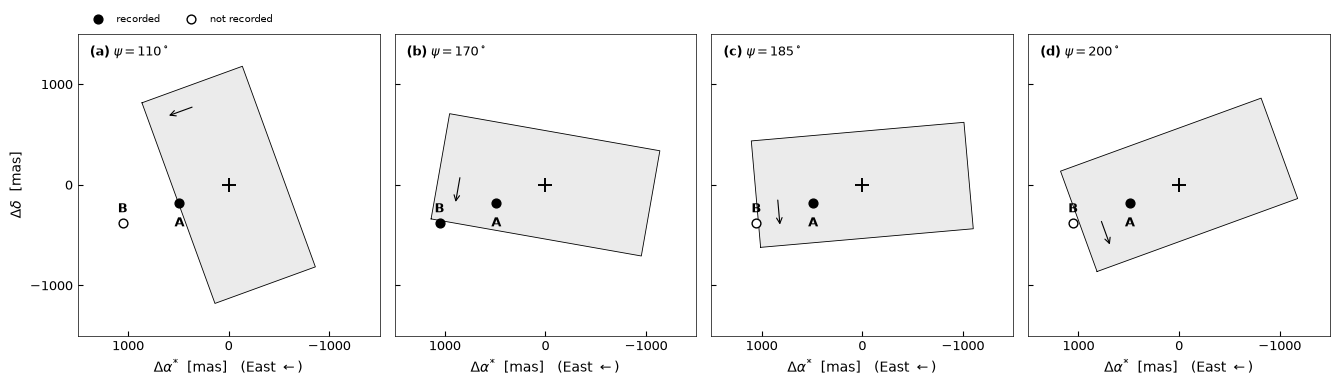

In [14]:
# the first figure, (a) to (d): the window's footprint (gray strip) at four scan angles, the scan direction
# (arrow), the primary (plus) and the two companions: a filled dot where the window records the companion
fig, axes = plt.subplots(1, 4, figsize=(13.5, 3.9), sharex=True, sharey=True)
# the strip's four corners, each as (sign along the scan, sign across it); the first is repeated to close the
# outline
CORNER_SIGNS = ((1, 1), (1, -1), (-1, -1), (-1, 1), (1, 1))
# the two companions, each as (sky position, name, where the name is written: 1 above the dot, -1 below it)
COMPANIONS = ((theta_edge, "A", -1), (theta_cut, "B", 1))
for ax, label, psi_deg in zip(axes, "abcd", (110.0, 170.0, 185.0, 200.0)):
    # step 1, the scan of this panel: its angle [rad] and its two unit vectors
    psi_j = np.deg2rad(psi_deg)
    along = np.array([np.sin(psi_j), np.cos(psi_j)])             # unit vector along the scan, (dra*, ddec)
    across = np.array([-np.cos(psi_j), np.sin(psi_j)])           # unit vector across the scan

    # step 2, the strip: AL_HALF along the scan and AC_HALF across it, on either side of the primary
    corners = []
    for sign_along, sign_across in CORNER_SIGNS:
        corners.append(sign_along * AL_HALF * along + sign_across * AC_HALF * across)
    corners = np.array(corners)                                  # one row (dra*, ddec) per corner
    ax.fill(corners[:, 0], corners[:, 1], color="0.92", lw=0)
    ax.plot(corners[:, 0], corners[:, 1], "k", lw=0.6)

    # step 3, the arrow of the scan direction, drawn 850 mas to the side of the primary, and the primary
    arrow_tail = 50 * along + 850 * across
    arrow_head = 350 * along + 850 * across
    ax.annotate("", xy=arrow_head, xytext=arrow_tail, arrowprops=dict(arrowstyle="->", color="k", lw=0.8))
    ax.scatter(0, 0, **PRIMARY)

    # step 4, the two companions. *companion unpacks its (dra*, ddec); the window records a companion that is
    # within the along-scan reach and inside the across-scan width
    for companion, name, name_side in COMPANIONS:
        eta_companion = ins.project_al(*companion, psi_j)
        zeta_companion = -companion[0] * np.cos(psi_j) + companion[1] * np.sin(psi_j)
        is_recorded = (abs(eta_companion) < AL_REACH) and (abs(zeta_companion) < AC_HALF)
        if is_recorded:
            dot_face = "k"
        else:
            dot_face = "w"
        ax.scatter(*companion, marker="o", s=40, facecolor=dot_face, edgecolor="k", lw=1.0, zorder=5)
        if name_side > 0:
            name_offset = (0, 8)                                 # in points: above the dot
        else:
            name_offset = (0, -17)                               # below the dot
        ax.annotate(name, companion, textcoords="offset points", xytext=name_offset, ha="center", fontsize=9,
                    fontweight="bold")
    letter(ax, label, rf"$\psi = {psi_deg:.0f}^\circ$")
    ax.set(xlim=(1500, -1500), ylim=(-1500, 1500), xticks=(1000, 0, -1000), yticks=(-1000, 0, 1000),
           aspect="equal", xlabel=EAST)                          # east to the left
axes[0].set_ylabel(NORTH)
# two empty sets of points: they draw nothing and give the legend its two entries
axes[0].scatter([], [], marker="o", s=40, facecolor="k", edgecolor="k", lw=1.0, label="recorded")
axes[0].scatter([], [], marker="o", s=40, facecolor="w", edgecolor="k", lw=1.0, label="not recorded")
axes[0].legend(loc="lower left", bbox_to_anchor=(0.0, 1.0), ncol=2)
plt.tight_layout()
plt.show()

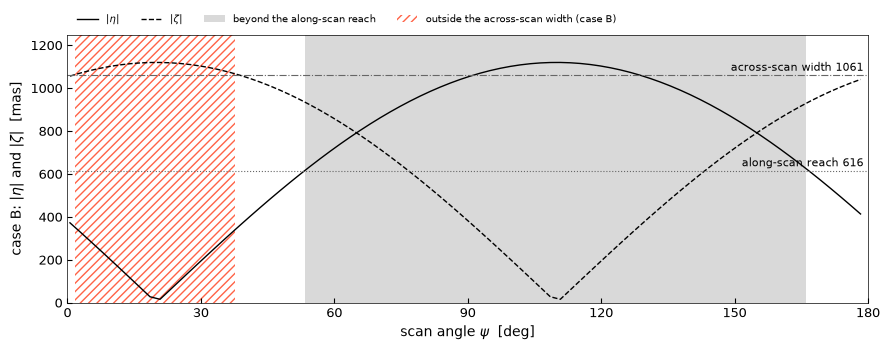

In [15]:
# the first figure, the wide panel: case B's |eta| and |zeta| around the half-turn, with the two limits.
# [:, 1] keeps the companion's column of the along-scan positions (column 0 is the primary)
fig, ax = plt.subplots(figsize=(9.0, 3.6))
psi_deg = np.degrees(EVEN)
# step 1, the three groups of windows as bands. Each of the 80 directions gets a band of 2.25 deg, 1.125 deg on
# either side of its angle: gray beyond the along-scan reach (state 0), hatched for case B (state 1), none where
# the window holds the companion (state 2)
for band_left, band_right, window_state in zip(psi_deg - 1.125, psi_deg + 1.125, state):
    if window_state == 0:
        ax.axvspan(band_left, band_right, color="0.85", lw=0)
    elif window_state == 1:
        ax.axvspan(band_left, band_right, facecolor="none", edgecolor=ACCENT, hatch="////", lw=0)

# step 2, the two curves: |eta| of the companion (eta_cut, its column of the along-scan positions) and |zeta|
ax.plot(psi_deg, np.abs(eta_cut), color="k", lw=1, label=r"$|\eta|$")
ax.plot(psi_deg, np.abs(zeta), color="k", ls="--", lw=1, label=r"$|\zeta|$")

# step 3, the two limits, with their values
ax.axhline(AL_REACH, color="0.4", ls=":", lw=0.8)
ax.axhline(AC_HALF, color="0.4", ls="-.", lw=0.8)
ax.text(179, AL_REACH + 20, f"along-scan reach {AL_REACH:.0f}", ha="right", fontsize=8)
ax.text(179, AC_HALF + 20, f"across-scan width {AC_HALF:.0f}", ha="right", fontsize=8)

# step 4, the legend's entries for the bands (two empty areas: they draw nothing), the axes and the legend
ax.fill_between([], [], color="0.85", lw=0, label="beyond the along-scan reach")
ax.fill_between([], [], facecolor="none", edgecolor=ACCENT, hatch="////", lw=0,
                label="outside the across-scan width (case B)")
ax.set(xlabel=r"scan angle $\psi$  [deg]", ylabel=r"case B: $|\eta|$ and $|\zeta|$  [mas]", xlim=(0, 180),
       xticks=np.arange(0, 181, 30), ylim=(0, 1250))
ax.legend(loc="lower left", bbox_to_anchor=(0.0, 1.0), ncol=4)
plt.tight_layout()
plt.show()

**The second figure.** Panels (a) and (b) are case A: the window at ψ = 110°,
with the companion cut by the edge (the gray bands are the sky beyond the
last sample; the dotted lines are the primary, gray, and the companion,
tomato), and the window at ψ = 200°, with the companion on top of the
primary. Panel (c) is case A sample by sample: the recorded fraction
(black, left axis) and the inward shift of the recorded center (tomato,
right axis) against the source's distance from the window's middle, with
the last sample center dotted. Panel (d) is case B: for each of the 80
directions of the half-turn, whether the window holds the companion
(black), misses it across the scan (tomato, the case B windows), or never
reached it along the scan (gray). The printed lines give panel (c) at four
distances.

In [16]:
# Case A, sample by sample: the recorded fraction and the inward shift of the
# recorded center against |eta|, on a fine grid of source positions.
etas = np.linspace(300.0, 600.0, 301)                         # the source's distance from the window's middle [mas]
# columns[n, k]: the fraction of the flux of a source at etas[k] that sample n records
columns = inst.design_columns(etas)
recorded_fraction = columns.sum(axis=0)                       # summed over the samples: one number per position
# the recorded center [mas]: the mean of the samples' positions, each weighted by its fraction. grid[:, None]
# makes the samples' positions a column, one per row of `columns`; np.maximum(..., 1e-300) guards a division by 0
recorded_center = (grid[:, None] * columns).sum(axis=0) / np.maximum(recorded_fraction, 1e-300)
for eta_printed in (450.0, 480.0, 500.0, 520.0):
    i = np.argmin(np.abs(etas - eta_printed))                 # i: the index of the position nearest to eta_printed
    inward_shift = etas[i] - recorded_center[i]
    print(f"case A, |eta| = {eta_printed:.0f} mas: recorded fraction {recorded_fraction[i]:.3f}, "
          f"recorded center shifted inward by {inward_shift:5.1f} mas")

case A, |eta| = 450 mas: recorded fraction 0.981, recorded center shifted inward by   2.2 mas
case A, |eta| = 480 mas: recorded fraction 0.906, recorded center shifted inward by   8.5 mas
case A, |eta| = 500 mas: recorded fraction 0.789, recorded center shifted inward by  17.0 mas
case A, |eta| = 520 mas: recorded fraction 0.612, recorded center shifted inward by  29.2 mas


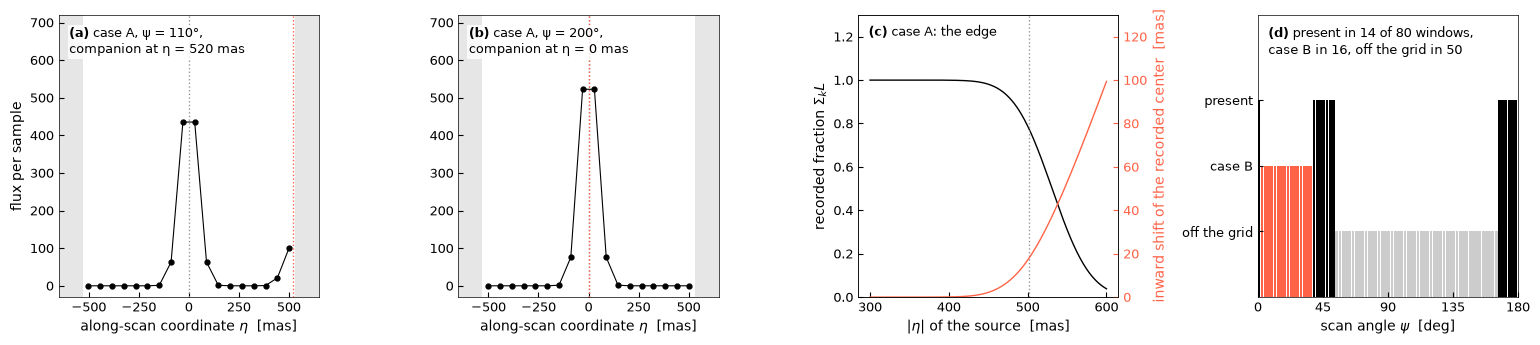

In [17]:
# the second figure. (a), (b): case A's window at two scan angles, with the primary (gray) and the companion
# (tomato) dotted; (c): the recorded fraction and the inward shift; (d): case B's three groups of windows over
# the half-turn
fig, axes = plt.subplots(1, 4, figsize=(15.5, 3.5))
# step 1, (a) and (b): the noise-free window of case A at two scan angles, along the pair axis and across it
two_angles = np.deg2rad([110.0, 200.0])
two_windows = windows_of(theta_edge, two_angles)
sources_edge = np.vstack([[0.0, 0.0], theta_edge])            # row 0 the primary, row 1 the companion: (dra*, ddec)
for ax, label, psi_j, window in zip(axes[:2], "ab", two_angles, two_windows):
    # the sky beyond the window's two edges (half a sample past the last and the first sample center), in gray
    ax.axvspan(grid[-1] + pitch / 2, 650, color="0.9", lw=0)
    ax.axvspan(-650, grid[0] - pitch / 2, color="0.9", lw=0)
    ax.plot(grid, window, "ko-", ms=3.5, lw=0.8)
    # the along-scan positions of the two sources: the primary's dotted gray, the companion's dotted tomato
    eta_sources = ins.project_al(sources_edge[:, 0], sources_edge[:, 1], psi_j)
    for eta_source, line_color in zip(eta_sources, ("0.6", ACCENT)):
        ax.axvline(eta_source, color=line_color, ls=":", lw=1)
    eta_companion = ins.project_al(*theta_edge, psi_j)        # *theta_edge unpacks the companion's (dra*, ddec)
    letter(ax, label, f"case A, ψ = {np.degrees(psi_j):.0f}°,\ncompanion at η = {eta_companion:.0f} mas")
    ax.set(xlim=(-650, 650), ylim=(-30, 720), xlabel=r"along-scan coordinate $\eta$  [mas]")
axes[0].set_ylabel("flux per sample")

# step 2, (c): the recorded fraction (black, left axis) and the inward shift of the recorded center (tomato,
# right axis); the dotted line is the last sample center
ax = axes[2]
ax.plot(etas, recorded_fraction, "k", lw=1)
ax.axvline(grid[-1], color="0.6", ls=":", lw=1)
ax.set(xlabel=r"$|\eta|$ of the source  [mas]", ylabel=r"recorded fraction $\Sigma_k L$", ylim=(0, 1.3))
letter(ax, "c", "case A: the edge")
ax_shift = ax.twinx()                                         # a second vertical axis on the same panel
ax_shift.plot(etas, etas - recorded_center, color=ACCENT, lw=1)
ax_shift.set_ylabel("inward shift of the recorded center  [mas]", color=ACCENT)
ax_shift.set_ylim(0, 130)
ax_shift.tick_params(axis="y", colors=ACCENT)

# step 3, (d): one bar per direction, its height and its color by the window's state (0, 1 or 2). STATE_COLORS
# is a table from the state to the bar's color; STATE_COLORS[state] takes one color per window
ax = axes[3]
STATE_COLORS = np.array(["0.8", ACCENT, "k"])
ax.bar(np.degrees(EVEN), state + 1.0, width=2.0, color=STATE_COLORS[state])
ax.set(xlabel=r"scan angle $\psi$  [deg]", xlim=(0, 180), xticks=np.arange(0, 181, 45), ylim=(0, 4.3),
       yticks=[1, 2, 3], yticklabels=["off the grid", "case B", "present"])
letter(ax, "d", f"present in {holds_companion.sum()} of 80 windows,\n"
                f"case B in {case_b.sum()}, off the grid in {np.sum(~on_grid)}")
plt.tight_layout()
plt.show()

## 2. The two images

*Paper: App. C.2, Eq. C.3 (the inverse Radon transform) and its text on faststack; the finite window size is named there as a departure from ideal projections, the two cases are not in the paper.*

**What they assume.** The inverse Radon transform lays each window's
filtered projection back along its line, and faststack reads each window's
sample at each pixel. Both treat the window as the whole scan line: every
sample is laid back, and every pixel reads a sample from every window.

**What they return.** Case A: in the scans along the pair axis the
companion's light is partly off the grid and nothing can restore it. The
inverse Radon transform shows the clipped projections as a shadow running
from the companion outward along those scans; faststack, which keeps the
lowest samples, hardly changes, because the clipped samples are a few among
eighty. The flux integrated around the companion in the inverse Radon
transform stays within a few percent, because only a few scans clip it.
Case B: only 14 of 80 windows hold the companion, and 16 more have
background where the images expect its light. The inverse Radon transform
shows it at a sixth of its flux, with streaks along the few scans that
hold it. For faststack the windows that lack the companion are the lowest
values at its pixel; they set r₀ near zero and the companion's own light is
weighted away as if it were the primary's. The companion vanishes from the
picture.

**Do they warn.** No. Neither image has a residual or a χ²; the picture
simply shows less.

In [18]:
# the noise-free windows of the control, case A and case B, each with its truth, the half-size of its image
# [mas] and its pixel [mas]; case B's windows hold the companion only where `present` says so
rng = np.random.default_rng(2)                                # not used: the windows of this cell are noise-free
windows_control = windows_of(theta, EVEN)
windows_edge = windows_of(theta_edge, EVEN)
windows_cut = windows_of(theta_cut, EVEN, flux=flux_b, present=present)
# cases: a table of one row per case. A row holds the case's name, its windows, its companion's (dra*, ddec)
# [mas], the half-size of its image [mas], the pixel of its image [mas] and its companion's flux
cases = (("control, 200 mas", windows_control, theta, 600.0, step, flux[1]),
         ("case A, 520 mas, at the edge", windows_edge, theta_edge, 600.0, step, flux[1]),
         (f"case B, 1120 mas, in {holds_companion.sum()} windows", windows_cut, theta_cut, 1300.0, 2 * step,
          flux_b[1]))

control, 200 mas                          : inverse Radon flux within 120 mas of the companion  213.5 (unclipped: 196.3), peak there 0.0174 flux/mas²; faststack at the companion 105 flux per sample
case A, 520 mas, at the edge              : inverse Radon flux within 120 mas of the companion  208.7 (unclipped: 196.3), peak there 0.0171 flux/mas²; faststack at the companion 103 flux per sample
case B, 1120 mas, in 14 windows           : inverse Radon flux within 120 mas of the companion   62.7 (unclipped: 392.6), peak there 0.0042 flux/mas²; faststack at the companion 0 flux per sample


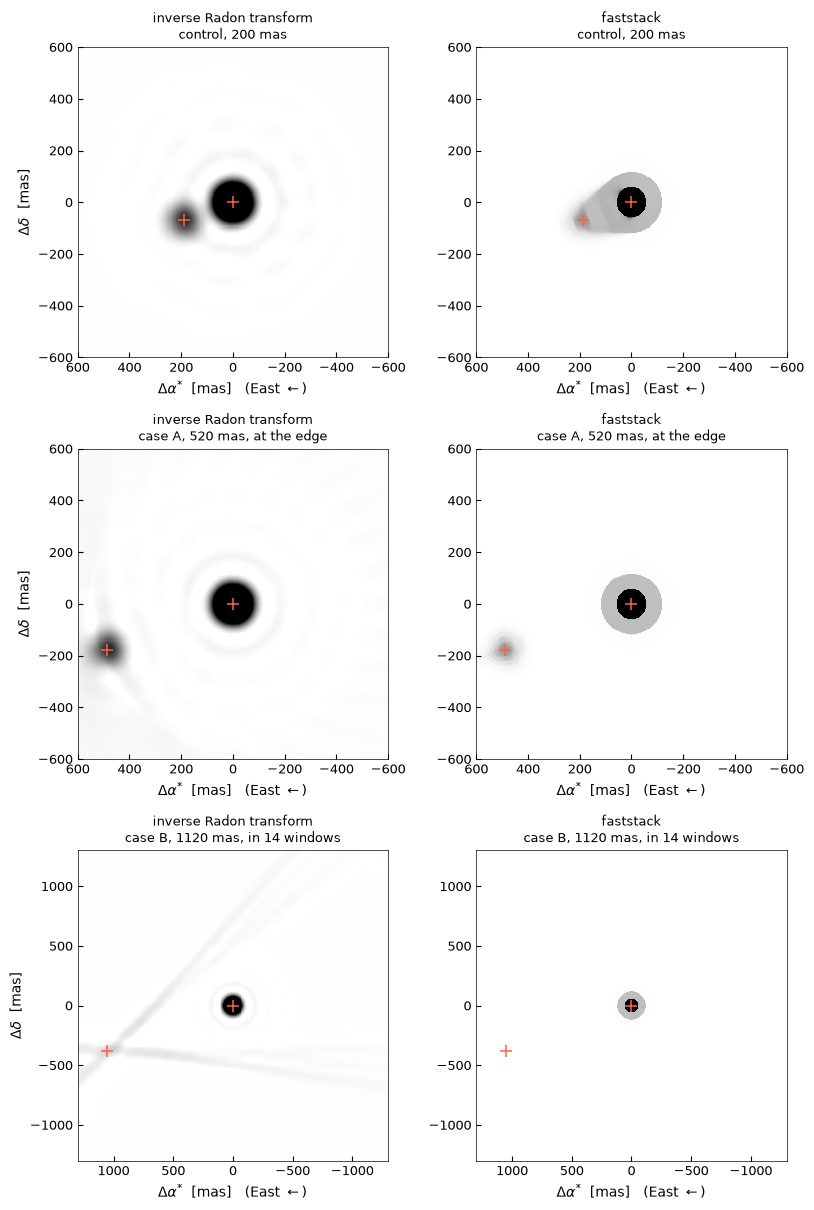

In [19]:
# for each case: the inverse Radon transform and faststack on the case's grid; the image's flux within 120 mas
# of the companion (the boolean mask `disc`) and its peak there; faststack at the companion's pixel (row
# companion_row, column companion_column). radon.faststack returns four things; `_` drops the three that are
# not the image
fig, axes = plt.subplots(3, 2, figsize=(8.4, 12.2))
for row, (name, wins, companion, half_image, step_image, companion_flux) in zip(axes, cases):
    # step 1, the two images of the case's windows, on its own sky grid
    image, axis = radon.filtered_backprojection(EVEN, wins, inst, half_image, step_image)
    stack, _, _, _ = radon.faststack(EVEN, wins, inst, half_image, step_image)

    # step 2, the inverse Radon image near the companion. disc: True for the pixels within 120 mas of it. The
    # flux there is the sum of those pixels [flux/mas^2] times a pixel's area [mas^2]. Without clipping, a
    # Gaussian of sigma_lsf holds the fraction 1 - exp(-r^2 / (2 sigma_lsf^2)) of its flux within radius r
    sky_x, sky_y = np.meshgrid(axis, axis)                    # dra* and ddec of every pixel [mas]
    disc = np.hypot(sky_x - companion[0], sky_y - companion[1]) < 120.0
    flux_in_disc = np.sum(image[disc]) * step_image ** 2
    flux_unclipped = (1 - np.exp(-0.5 * (120 / sigma_lsf) ** 2)) * companion_flux
    peak_in_disc = image[disc].max()

    # step 3, faststack at the companion's pixel: the row nearest to its ddec, the column nearest to its dra*;
    # a negative value is printed as 0
    companion_row = np.argmin(np.abs(axis - companion[1]))
    companion_column = np.argmin(np.abs(axis - companion[0]))
    stack_at_companion = max(stack[companion_row, companion_column], 0)
    print(f"{name:42s}: inverse Radon flux within 120 mas of the companion {flux_in_disc:6.1f} "
          f"(unclipped: {flux_unclipped:.1f}), peak there {peak_in_disc:.4f} flux/mas²; "
          f"faststack at the companion {stack_at_companion:.0f} flux per sample")

    # step 4, the two panels of the case, with the primary and the companion marked
    marks = np.vstack([[0.0, 0.0], companion])
    show(row[0], image, axis, f"inverse Radon transform\n{name}", marks, vmax=0.02)
    show(row[1], stack, axis, f"faststack\n{name}", marks, vmax=250)
    row[0].set_ylabel(NORTH)
plt.tight_layout()
plt.show()

## 3. The map of detections

*Paper: Sect. 3.3, Eq. 13 (the map). The map of a source that is missing from windows is not in the paper; it is here to show what a missing observation costs.*

**What it assumes.** Each detection is one line of the sky; the map sums
their ridges. A window that delivers no detection adds nothing.

**What it returns.** Case A: the windows that clip the companion still
resolve it, and the map's crossing is as sharp as the control's. Case B:
the windows the companion is missing from deliver no detection; the map
has 10 lines, in two bundles on either side of the perpendicular, and they
cross at the truth within 3 mas. A missing observation costs the map a
line and nothing else; the few lines left cost it resolution along the
pair axis.

**Does it warn.** Not by itself, but the count of lines per window is
visible, and a pipeline that expects a detection from every window sees the
gap.

control                         : 76 detections, sigma up to 24.2 mas; peak (186, -70) vs truth (188, -68), width 6.9 mas
case A, at the edge             : 78 detections, sigma up to 14.8 mas; peak (488, -180) vs truth (489, -178), width 7.5 mas
case B, 1120 mas                : 10 detections, sigma up to 13.6 mas; peak (1052, -386) vs truth (1052, -383), width 2.2 mas


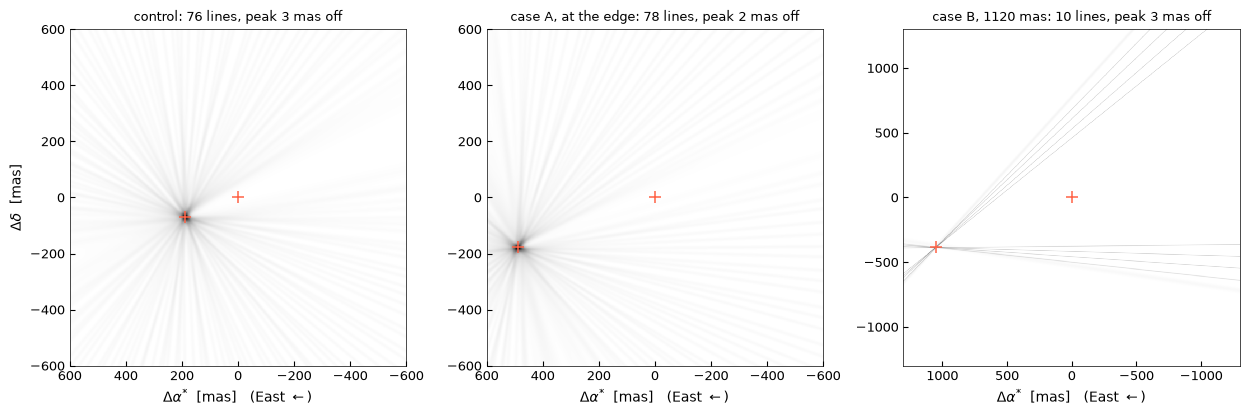

In [20]:
# The map of the control, case A and case B: the number of lines and the peak. bp.map_peak returns the peak's
# position, its width, the map and the map's axis; case B gets the larger grid (half-size 1300 mas)
fig, axes = plt.subplots(1, 3, figsize=(12.6, 4.4))
# one row per case: its name, its companion's (dra*, ddec) [mas], which source is in which window (None: every
# source in every window), its fluxes, and the half-size of its map [mas]
MAP_CASES = (("control", theta, None, flux, 600.0),
             ("case A, at the edge", theta_edge, None, flux, 600.0),
             ("case B, 1120 mas", theta_cut, present, flux_b, 1300.0))
for ax, (name, companion, in_window, case_flux, half_map) in zip(axes, MAP_CASES):
    # the teaching detections of the case (the stand-in, not a reduction of windows), and their map on a
    # pixel of 2 mas
    d_psi, d_eta, d_sigma = detections(companion, EVEN, flux=case_flux, present=in_window)
    peak, width, sky_map, map_axis = bp.map_peak(d_psi, d_eta, d_sigma, half_map, 2.0)
    # truth: the distance of the map's peak from the companion's true position [mas]
    peak_error = np.array(peak) - companion
    peak_distance = np.hypot(peak_error[0], peak_error[1])
    print(f"{name:32s}: {d_psi.size} detections, sigma up to {d_sigma.max():.1f} mas; "
          f"peak ({peak[0]:.0f}, {peak[1]:.0f}) vs truth ({companion[0]:.0f}, {companion[1]:.0f}), "
          f"width {width:.1f} mas")
    marks = np.vstack([[0.0, 0.0], companion])                # the primary at the origin, and the companion
    show(ax, sky_map, map_axis, f"{name}: {d_psi.size} lines, peak {peak_distance:.0f} mas off", marks)
axes[0].set_ylabel(NORTH)
plt.tight_layout()
plt.show()

## 4. The joint fit

*Paper: Sect. 4.3, Eq. 18 (the joint likelihood, every source in every window). The truncated column and the missing source are not in the paper; they are here to show where that likelihood holds and where it fails.*

**What it assumes.** The likelihood renders every source through
`inst.design_columns` on the finite grid, so the truncated column *is* the
model of an edge source: the flux loss and the inward shift are expected.
Across the scan it assumes every source in every window.

**What it returns.** Case A: no bias at the edge and beyond it, and a
Fisher error a little larger, the price of the information that fell off
the grid. Case B: in the 16 windows it is missing from, the fit expects the
companion's light at |η| up to 360 mas, finds none, and compromises: the
companion's flux drops from 400 to 145, its position moves by 20 mas
along the pair axis, four error bars, and the error bar does not know.

**Does it warn.** Case A: nothing to warn about. Case B: yes, χ²/dof
reaches 3.4, carried by the 16 windows of the conflict.

**The wrong remedy.** The tempting shortcut for the edge is to drop every
window in which the companion's recorded fraction falls below some level.
That cut removes exactly the scans along the pair axis, and the error
ellipse stretches in the direction they measured. The full set, with the
truncated columns, loses only the information that was really lost: model
the truncation, do not mask it.

**The figure** marks the truth with a star and each fit with a cross, and
draws covariance ellipses at Mahalanobis radius 3 (the legend's 3σ), which in two dimensions enclose 98.9 % of the probability
([conventions](../../../docs/conventions.md)).

In [21]:
# case A: the joint fit at four separations, each started 10 mas off the truth. `least` is the smallest recorded
# fraction of the companion over the 80 windows ([:, 1] is the companion's design column, summed over the samples)
# rng_noise: seed 1, the noise of case A's windows. One generator serves the four separations in turn, so each
# separation has its own draw
rng_noise = np.random.default_rng(1)
print("case A (the edge), the fit at four separations:")
for rho in (200.0, 400.0, 480.0, 520.0):
    companion = pair(rho)
    # the recorded fraction of the companion in each window: the sum over the samples of its design column
    recorded_fractions = []
    for eta_j in joint.scene_positions_al(companion, EVEN):
        columns_j = inst.design_columns(eta_j)                # one row per sample, one column per source
        recorded_fractions.append(columns_j[:, 1].sum())
    least = min(recorded_fractions)
    # the noisy windows, and the fit started at the truth plus (8, -6) mas
    noisy_windows = windows_of(companion, EVEN, rng=rng_noise)
    start = companion + [8.0, -6.0]
    fit = joint.fit_joint(noisy_windows, EVEN, start, inst, sigma_noise)
    report(f"  {rho:.0f} mas, least recorded fraction {least:.2f}", fit, companion, DOF)

case A (the edge), the fit at four separations:
  200 mas, least recorded fraction 1.00  fit − truth (  0.09,  -0.11)   pulls (  0.1,  -0.1)   fluxes 999, 199   chi2/dof 1.02
  400 mas, least recorded fraction 1.00  fit − truth (  1.04,   0.02)   pulls (  1.4,   0.0)   fluxes 1002, 201   chi2/dof 0.95
  480 mas, least recorded fraction 0.91  fit − truth (  0.61,   0.84)   pulls (  0.8,   1.1)   fluxes 1003, 198   chi2/dof 1.02
  520 mas, least recorded fraction 0.61  fit − truth (  1.12,   0.39)   pulls (  1.3,   0.5)   fluxes 1001, 201   chi2/dof 1.03


In [22]:
# case B: the fit of the windows that all hold the companion, and of the windows of the true geometry; the same
# start, and theta_bound = 1400 mas so that the position may reach case B's separation
print(f"case B (1120 mas, companion flux {flux_b[1]:.0f}, the across-scan width at {AC_HALF:.0f} mas):")
# rng_noise: seed 2, the noise of case B's windows. The first 80 windows drawn are those that all hold the
# companion, the next 80 are those of the true geometry: the two sets have different noise
rng_noise = np.random.default_rng(2)
wins_full = windows_of(theta_cut, EVEN, flux=flux_b, rng=rng_noise)
wins_cut = windows_of(theta_cut, EVEN, flux=flux_b, rng=rng_noise, present=present)
start = theta_cut + [8.0, -6.0]                               # 10 mas from the truth
fit_full = joint.fit_joint(wins_full, EVEN, start, inst, sigma_noise, theta_bound=1400.0)
fit_cut = joint.fit_joint(wins_cut, EVEN, start, inst, sigma_noise, theta_bound=1400.0)
report("  no across-scan width (every window holds it)", fit_full, theta_cut, DOF)
report(f"  the true geometry, missing from {case_b.sum()} windows", fit_cut, theta_cut, DOF)

case B (1120 mas, companion flux 400, the across-scan width at 1061 mas):
  no across-scan width (every window holds it) fit − truth ( -0.47,   0.87)   pulls ( -0.3,   1.1)   fluxes 997, 396   chi2/dof 1.03
  the true geometry, missing from 16 windows fit − truth (-19.50,   7.64)   pulls ( -4.5,   3.8)   fluxes 994, 145   chi2/dof 3.38


In [23]:
# the wrong remedy on case A: keep only the windows that record at least 95 % of the companion's flux. `keep` is
# the mask of those windows; EVEN[~keep] are the dropped directions
# step 1, the recorded fraction of case A's companion in each window: the sum over the samples of its design
# column ([:, 1]; column 0 is the primary's)
fraction = []
for eta_j in joint.scene_positions_al(theta_edge, EVEN):
    columns_j = inst.design_columns(eta_j)
    fraction.append(columns_j[:, 1].sum())
fraction = np.array(fraction)
keep = fraction >= 0.95

# step 2, the angle of each dropped scan from the pair axis. A scan direction is a line, so psi and psi + 180 deg
# are the same: exp(2 i (psi - pa)) has twice the difference as its phase, np.angle folds that into -180 to
# 180 deg, and half of its absolute value is the angle between the two lines, 0 to 90 deg
dropped = EVEN[~keep]
twice_angle_deg = np.degrees(np.abs(np.angle(np.exp(2j * (dropped - pa)))))
widest_angle_deg = twice_angle_deg.max() / 2
print(f"the flux-loss cut on case A keeps {keep.sum()} of 80 windows, dropping the scans within "
      f"{widest_angle_deg:.0f}° of the pair axis")

the flux-loss cut on case A keeps 57 of 80 windows, dropping the scans within 26° of the pair axis


case A, all windows, truncation modeled : Fisher sigma (0.87, 0.78) mas, ellipse axes 0.76 and 0.88, ratio 1.16
case A, after the flux-loss cut         : Fisher sigma (1.08, 0.83) mas, ellipse axes 0.77 and 1.12, ratio 1.45


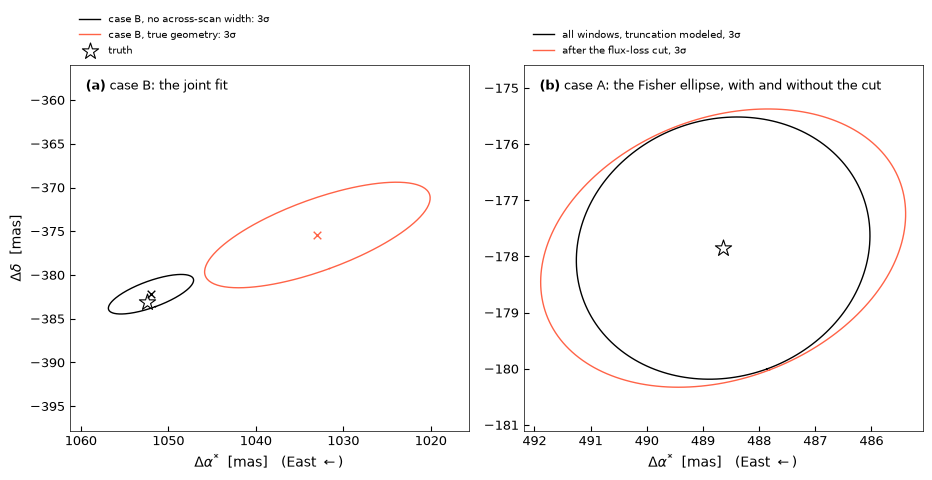

In [24]:
# the figure. (a): case B's two fits (crosses) with their 3-sigma ellipses, and the truth (star). (b): case A's
# Fisher ellipse from all windows and from the windows the cut keeps; cov[:2, :2] is the position's 2 x 2 block
fig, axes = plt.subplots(1, 2, figsize=(9.6, 4.9))
# step 1, (a): each fit of case B as a cross, with the ellipse of its own covariance at Mahalanobis radius 3
for name, fit, color in (("no across-scan width", fit_full, "k"), ("true geometry", fit_cut, ACCENT)):
    outline = ellipse(fit["cov"][:2, :2], fit["theta"], 3.0)
    axes[0].plot(outline[:, 0], outline[:, 1], color=color, lw=1, label=f"case B, {name}: 3σ")
    cross_style = dict(FIT, color=color, s=30, lw=1.0)        # the FIT marker in this fit's color, smaller, thinner
    axes[0].scatter(*fit["theta"], **cross_style)
axes[0].scatter(*theta_cut, **TRUTH, label="truth")
axes[0].set(xlabel=EAST, ylabel=NORTH)
axes[0].margins(0.12, 0.3)
axes[0].set_aspect("equal", adjustable="datalim")
axes[0].invert_xaxis()                                        # east to the left
letter(axes[0], "a", "case B: the joint fit")
axes[0].legend(loc="lower left", bbox_to_anchor=(0.0, 1.0))

# step 2, (b): the Fisher covariance of case A at the truth (a formula, no fit and no noise draw), from all the
# directions and from those the cut keeps. joint.joint_covariance(..., 2) returns the covariance of all the
# parameters and the 1-sigma of the first two, the position; variances are those along the ellipse's two axes
ELLIPSES = (("all windows, truncation modeled", EVEN, "k"), ("after the flux-loss cut", EVEN[keep], ACCENT))
for name, psi, color in ELLIPSES:
    fisher = joint.joint_fisher(theta_edge, flux, psi, inst, sigma_noise)
    cov, sigma_position = joint.joint_covariance(fisher, 2)
    variances = np.linalg.eigvalsh(cov[:2, :2])
    short_axis = np.sqrt(variances[0])
    long_axis = np.sqrt(variances[1])
    print(f"case A, {name:32s}: Fisher sigma ({sigma_position[0]:.2f}, {sigma_position[1]:.2f}) mas, "
          f"ellipse axes {short_axis:.2f} and {long_axis:.2f}, ratio {np.sqrt(variances[1] / variances[0]):.2f}")
    outline = ellipse(cov[:2, :2], theta_edge, 3.0)
    axes[1].plot(outline[:, 0], outline[:, 1], color=color, lw=1, label=f"{name}, 3σ")
axes[1].scatter(*theta_edge, **TRUTH)
axes[1].set(xlabel=EAST)
axes[1].margins(0.12, 0.3)
axes[1].set_aspect("equal", adjustable="datalim")
axes[1].invert_xaxis()                                        # east to the left
letter(axes[1], "b", "case A: the Fisher ellipse, with and without the cut")
axes[1].legend(loc="lower left", bbox_to_anchor=(0.0, 1.0))
plt.tight_layout()
plt.show()

## Summary

| atom | effect in this case | alarm | remedy |
|---|---|---|---|
| inverse Radon transform | A: a shadow along the clipping scans, flux kept within a few percent; B: the companion at a sixth of its level, with streaks | none | none in the image; a per-window membership would drop the absent windows' rays |
| faststack | A: hardly changed; B: the companion erased, its light treated as contamination | none | an across-scan width per window (dev's `ac_half`), so a window that did not cover the pixel contributes no sample |
| map of detections | A: unchanged; B: 10 lines in two bundles, same peak | the count of lines per window | none needed |
| joint fit | A: unbiased, error bar slightly larger; B: flux cut to about a third, position four error bars off, error bar unaware | A: none needed; B: χ²/dof ≈ 3 | a per-window source list in the design, so an absent source has no column; never a flux-loss cut |

## What this establishes

- Along the scan the window ends: within two LSF widths of the last sample
  a source loses recorded flux and its recorded center shifts inward. The
  design column carries both, so the joint fit is unbiased at the edge and
  beyond it; the images clip the source and cannot say so.
- Across the scan a source outside the window is a missing observation. In
  a window centered on the primary this happens for separations between
  1061 and 1186 mas, in the scans near the perpendicular to the pair. The
  likelihood of this package, which puts every source in every window, is
  biased by it and χ² says so; faststack erases such a source
  without a word; the map loses lines and nothing else.
- A flux-loss cut removes scan angles, not noise: it elongates the error
  ellipse where the truncation only widened it. Model the truncation and the
  membership; do not mask them.